In [1]:
from pathlib import Path
import numpy as np

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from SummuryDataCollect import collect_metrics_dataframe, plot_metrics_by_target, plot_model_feature_importance, plot_dual_scenario_auto_aligned
os.chdir(curdir)

In [2]:
name1A = 'JanisLike'
name1B = 'NotJanisLike'
name2A = 'No_Strict_2A'
name2B = 'Lauvian_2B'

ROOT_PATH = Path('../processed_data/Results/')

Scenario1A_path = Path('../processed_data/Results/JanisLike/')
Scenario1B_path = Path('../processed_data/Results/NotJanisLike/')
Scenario2A_path = Path('../processed_data/Results/No_Strict_2A/')
Scenario2B_path = Path('../processed_data/Results/Lauvian_2B/')

metrics1A_paths = list(Scenario1A_path.glob('**/final_metrics.csv'))
metrics1B_paths = list(Scenario1B_path.glob('**/final_metrics.csv'))
metrics2A_paths = list(Scenario2A_path.glob('**/final_metrics.csv'))
metrics2B_paths = list(Scenario2B_path.glob('**/final_metrics.csv'))

m1A = collect_metrics_dataframe(metrics1A_paths, name1A)
m1B = collect_metrics_dataframe(metrics1B_paths, name1B)
m2A = collect_metrics_dataframe(metrics2A_paths, name2A)
m2B = collect_metrics_dataframe(metrics2B_paths, name2B)

name_list = [name1A, name1B, name2A, name2B]
df_list = [m1A, m1B, m2A, m2B]

models_names = ['Classic', 'Lasso', 'Ridge', 'CatBoost', 'TreeBagging','MLP','CNN']

               JanisLike                


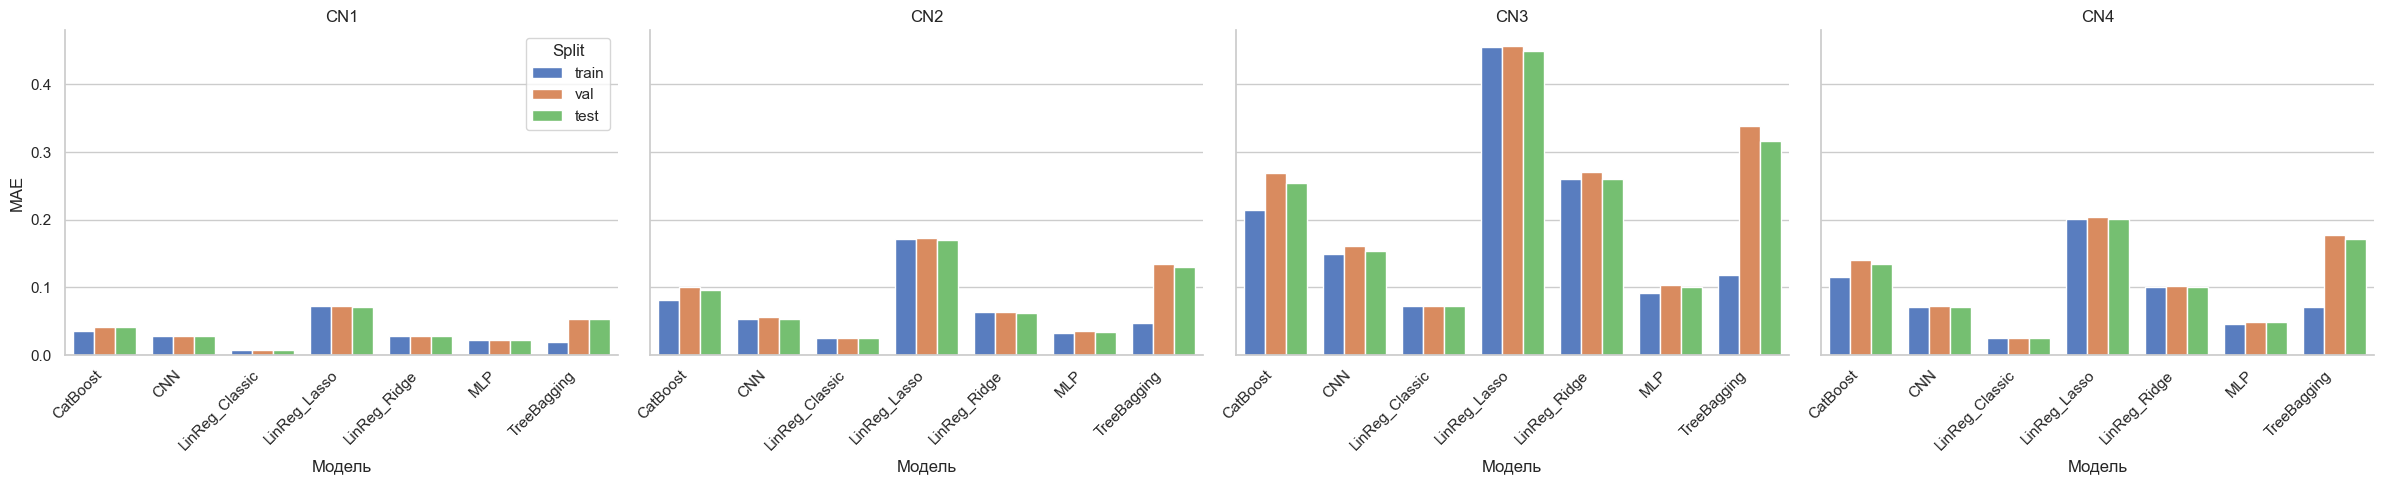

              NotJanisLike              


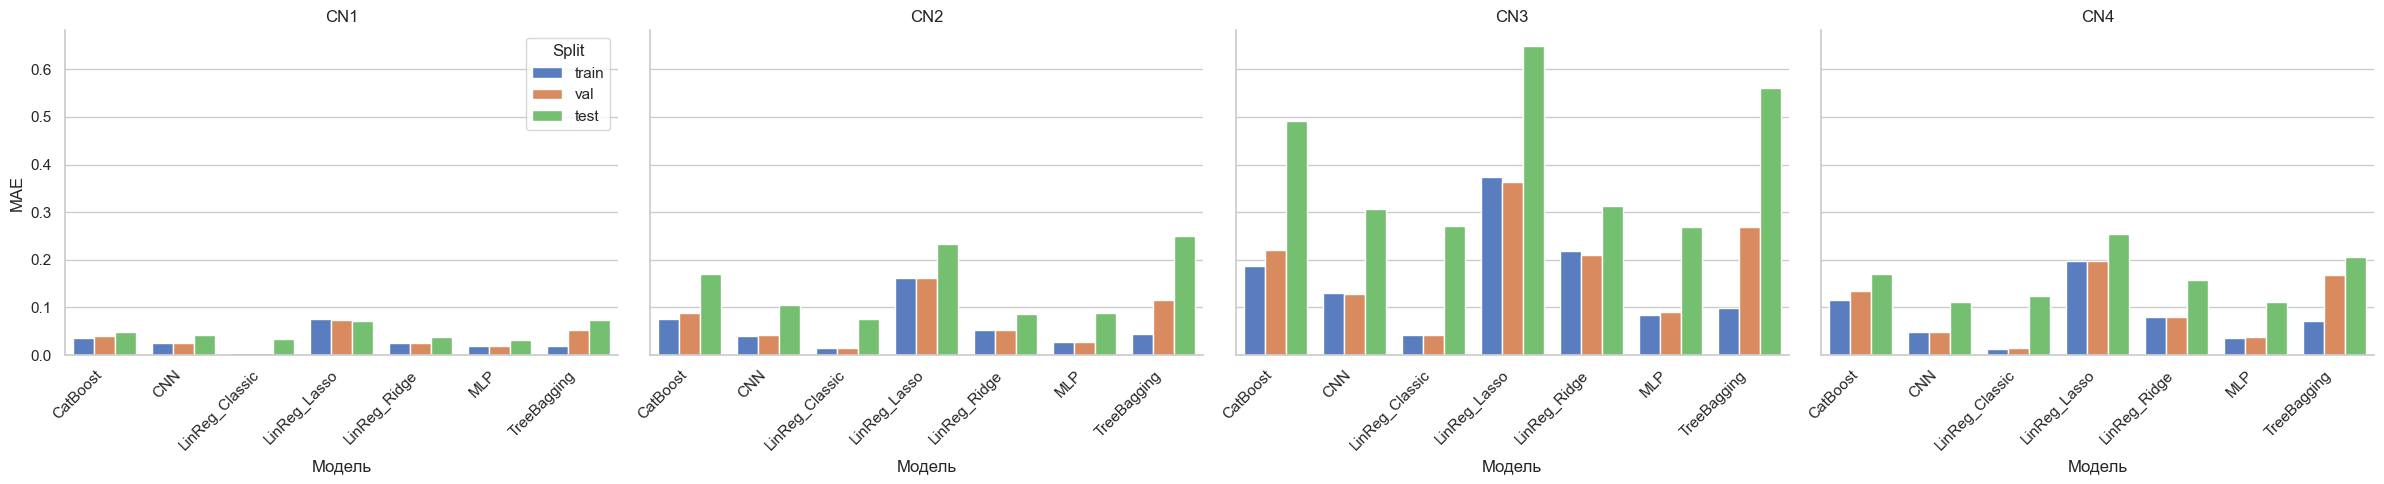

              No_Strict_2A              


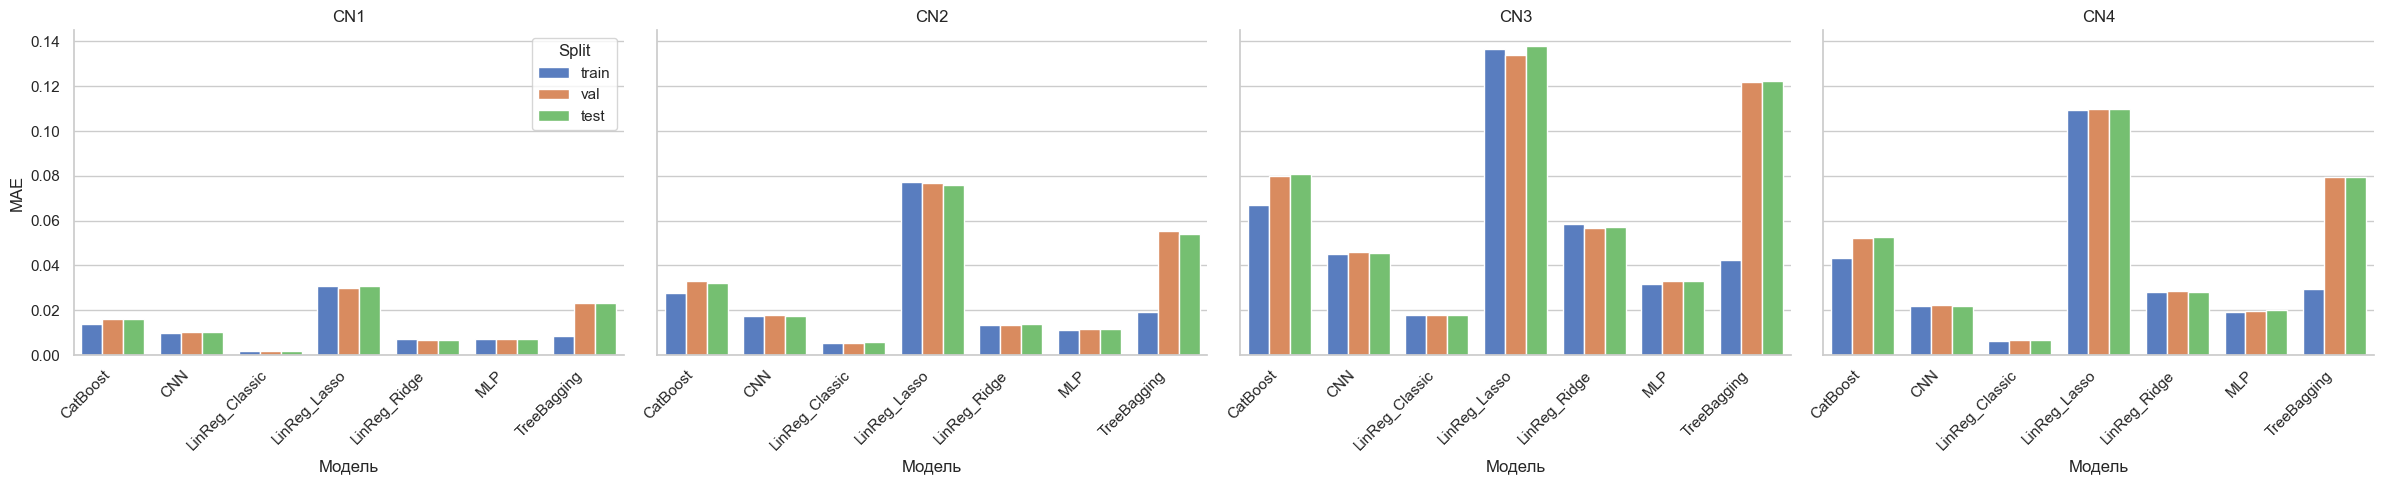

               Lauvian_2B               


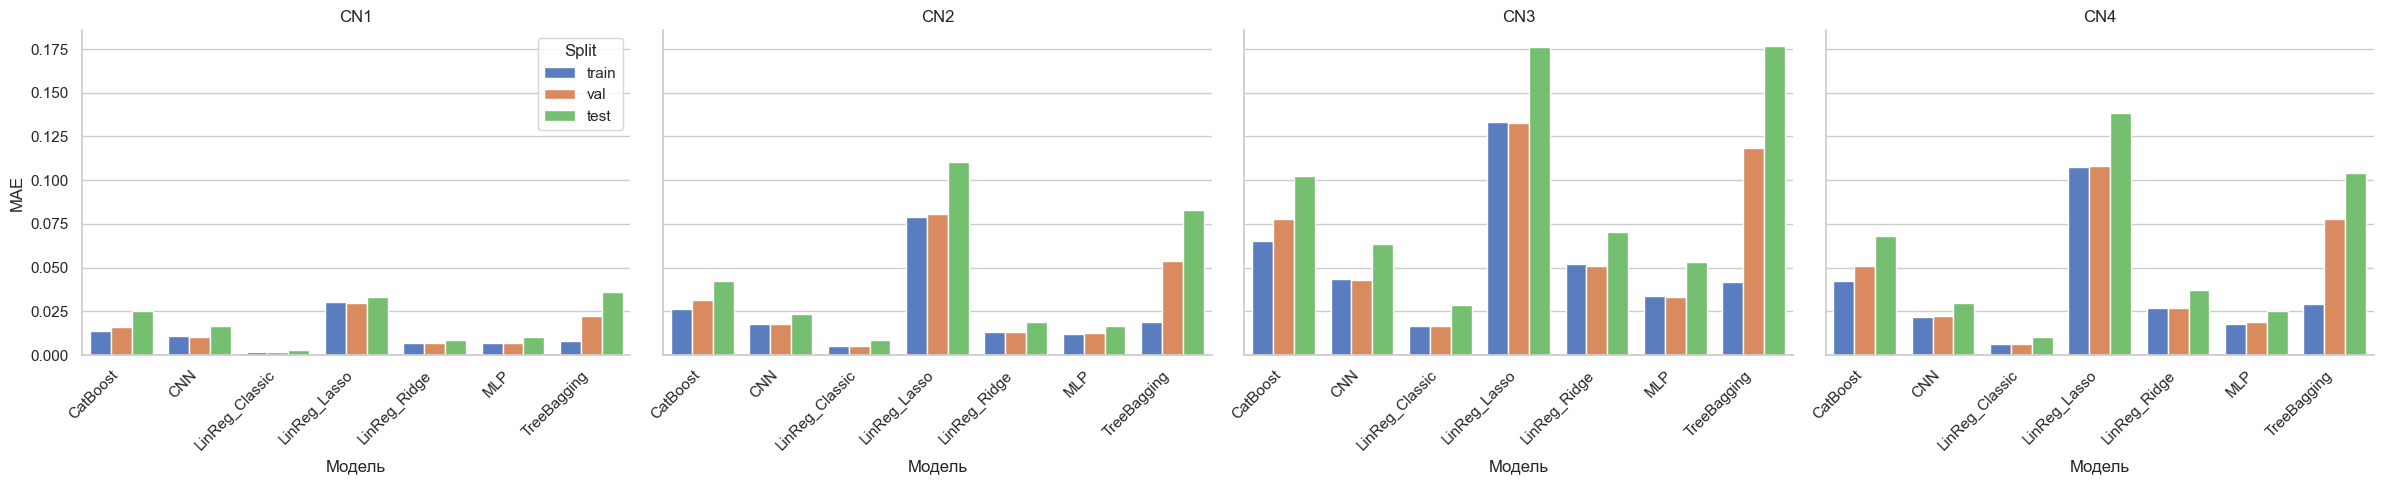

In [3]:
for name, df in zip(name_list, df_list):
    targets = ['CN1','CN2','CN3','CN4']
    metric = 'MAE'
    save_path = Path('../processed_data/Results/',name,f'{name}.png')
    print('='*40)
    print(f"{name:^40}")
    print('='*40)
    plot_metrics_by_target(df, metric_name=metric, target=targets, sharey=True, save_path=save_path)

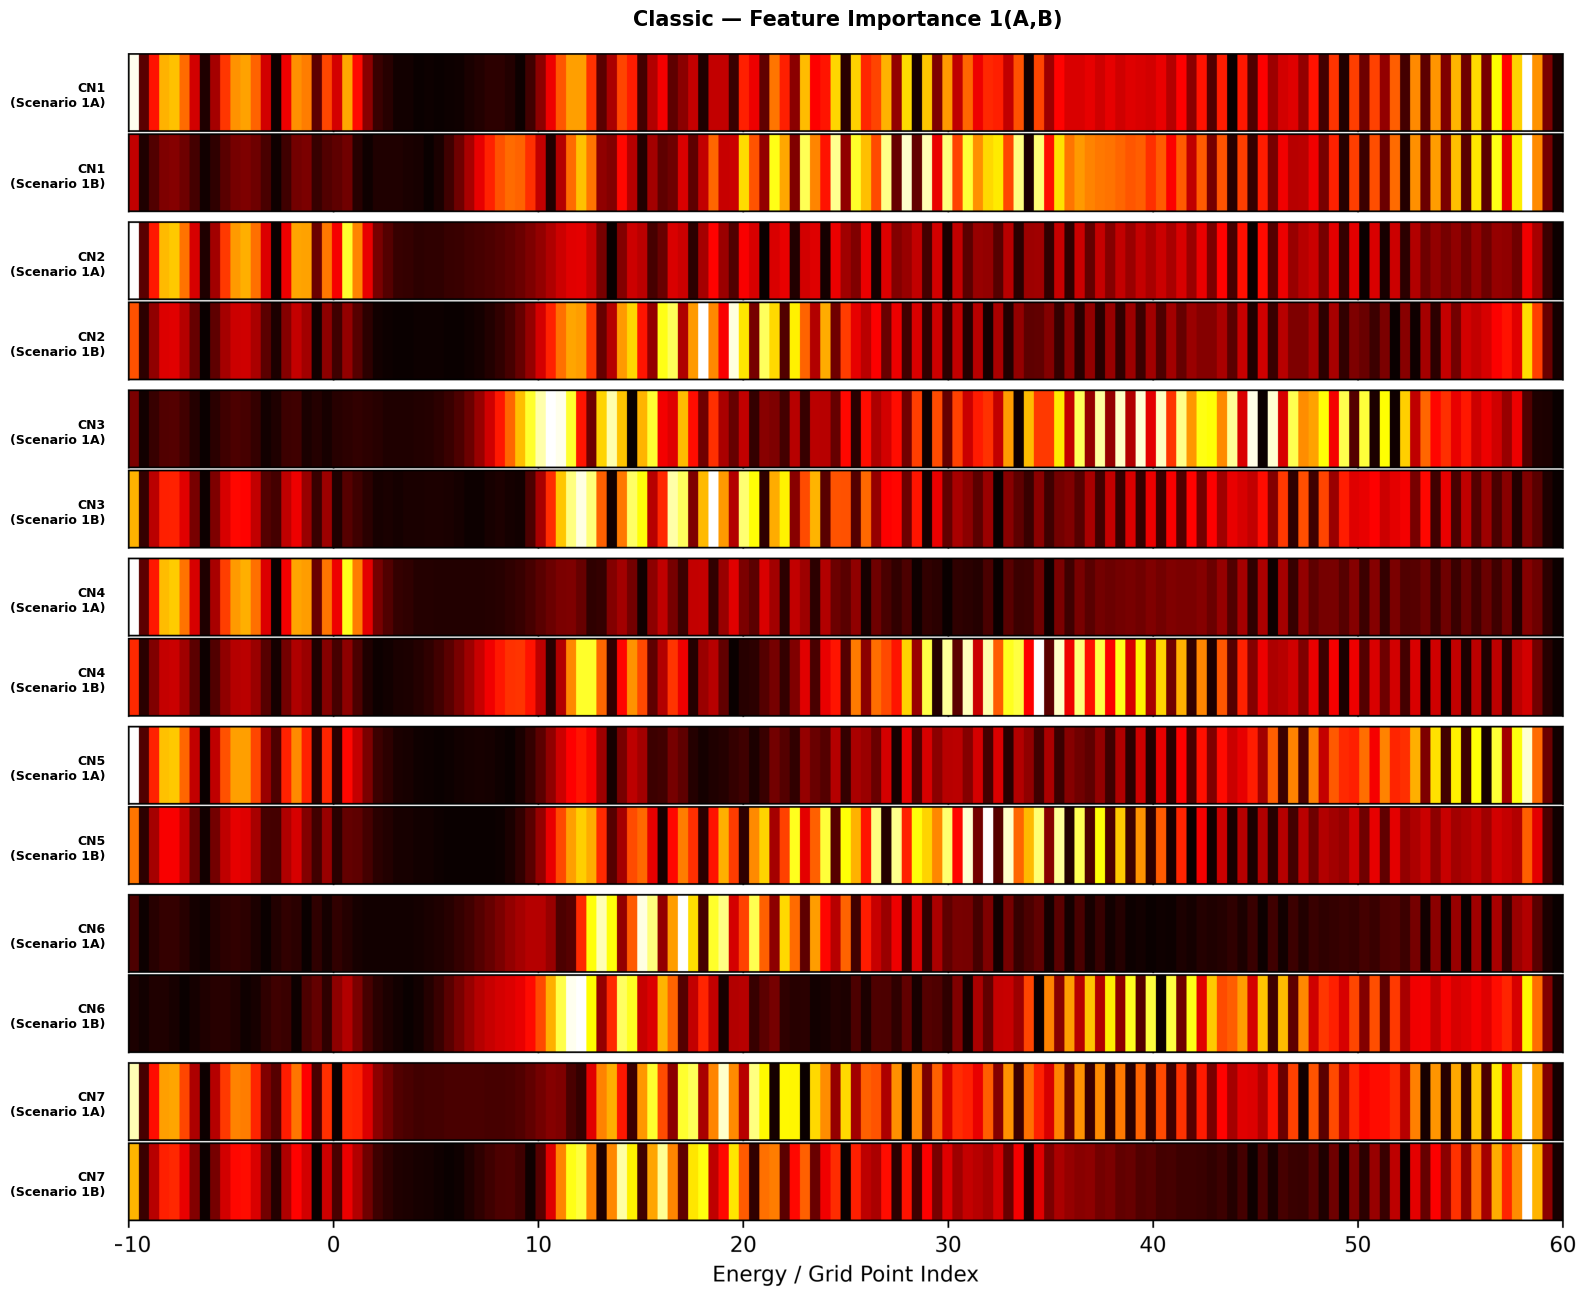

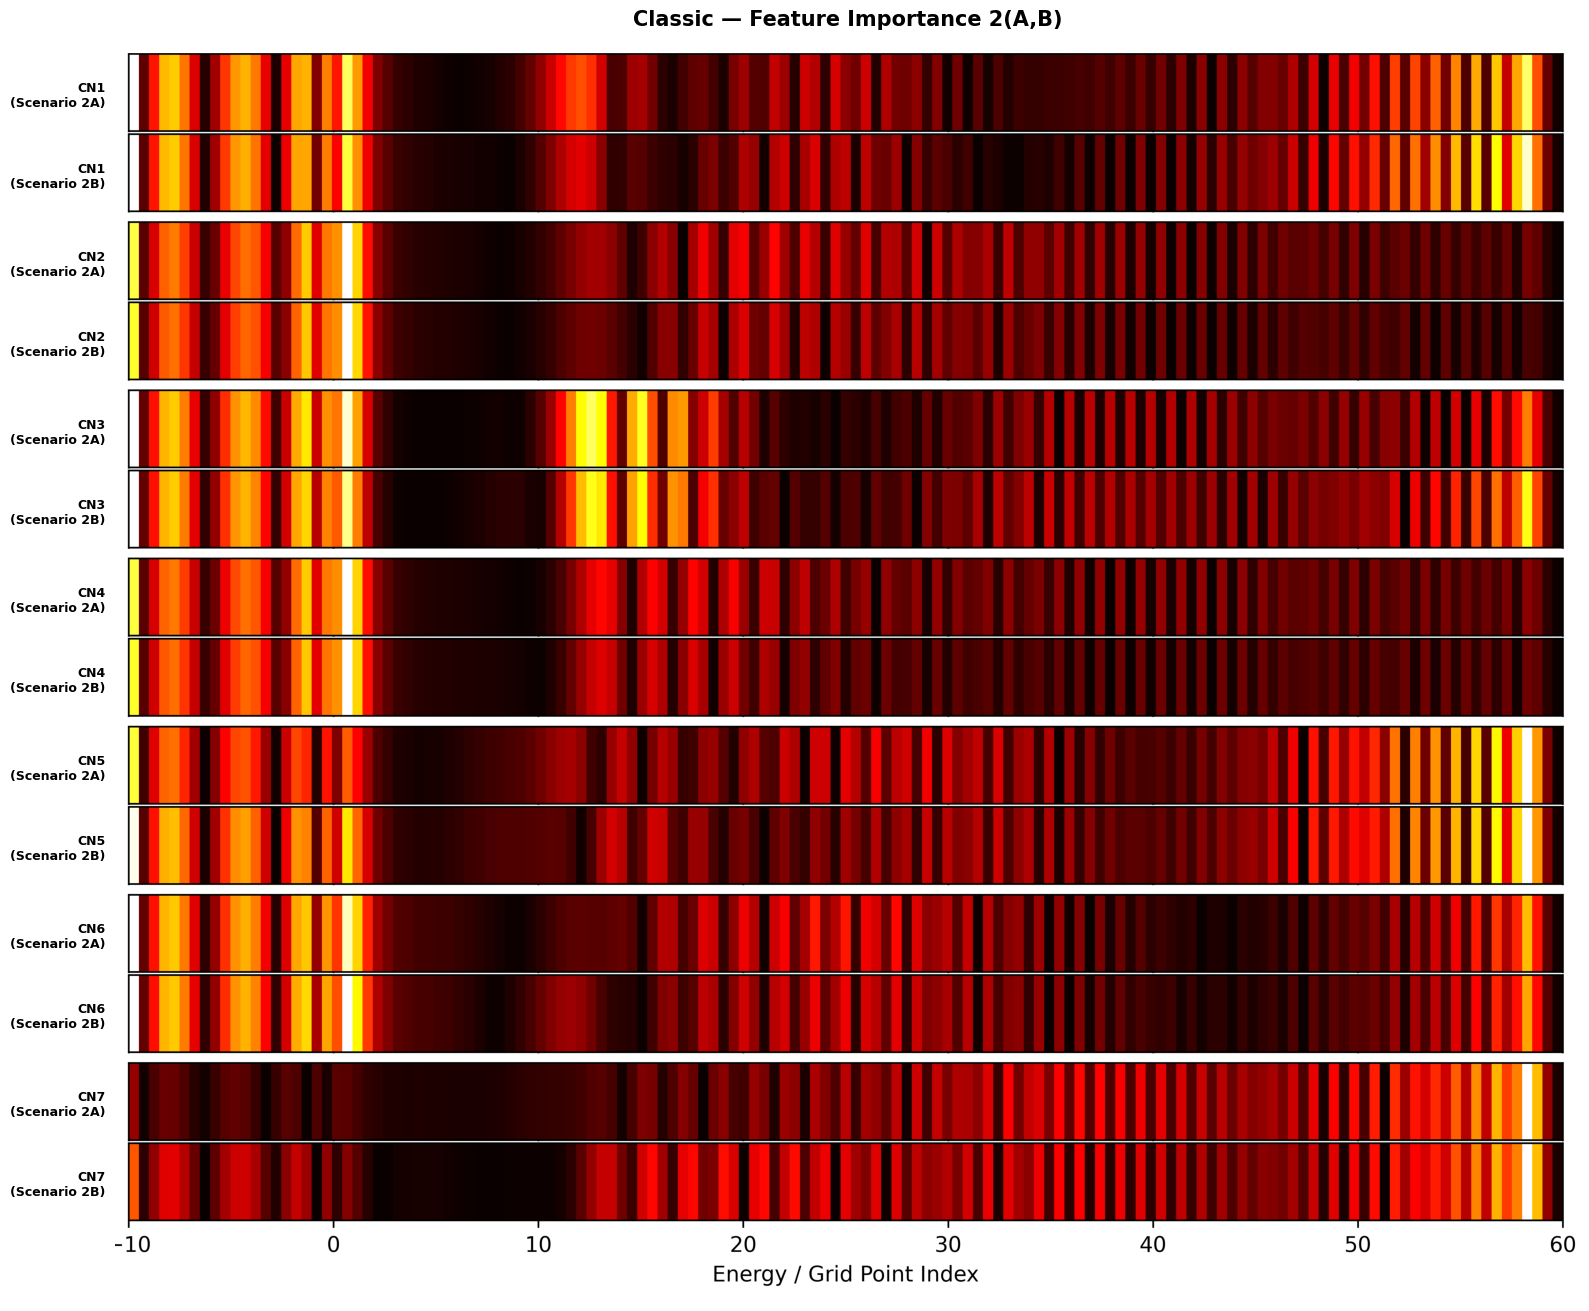

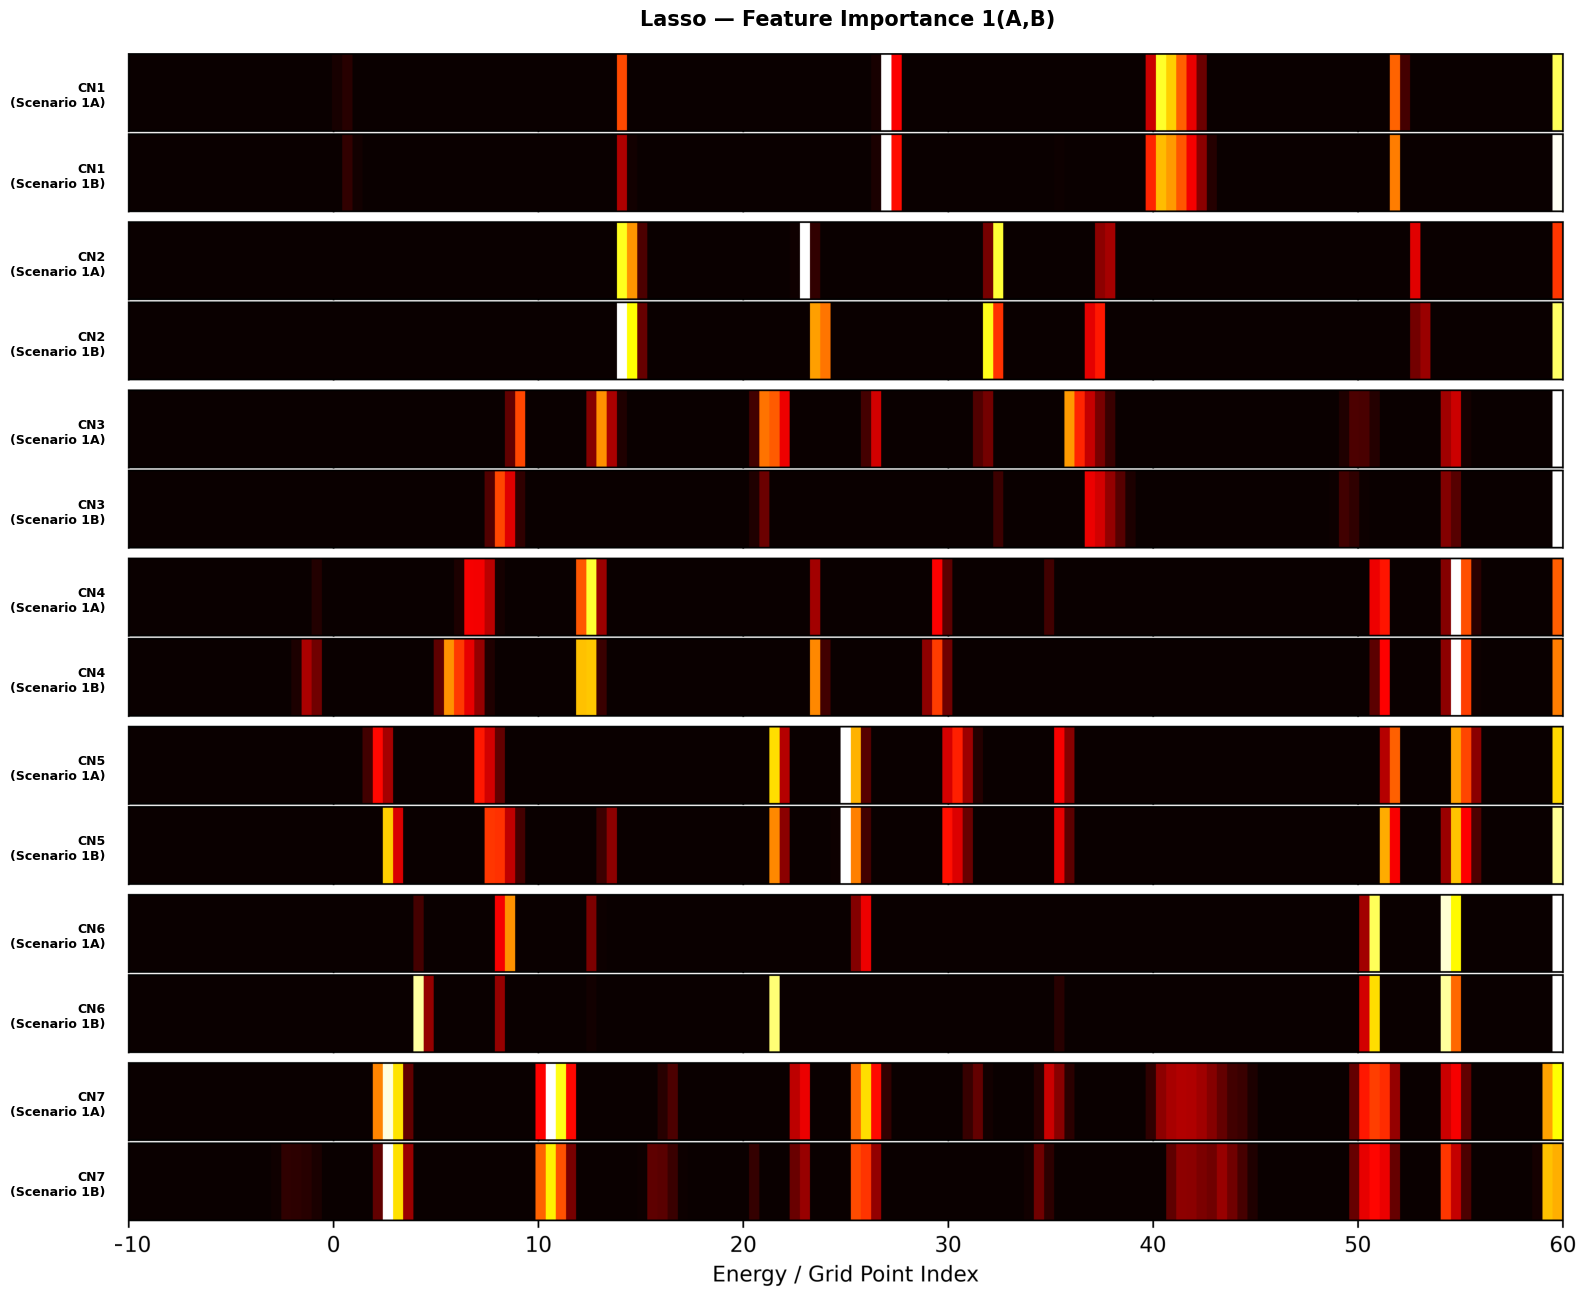

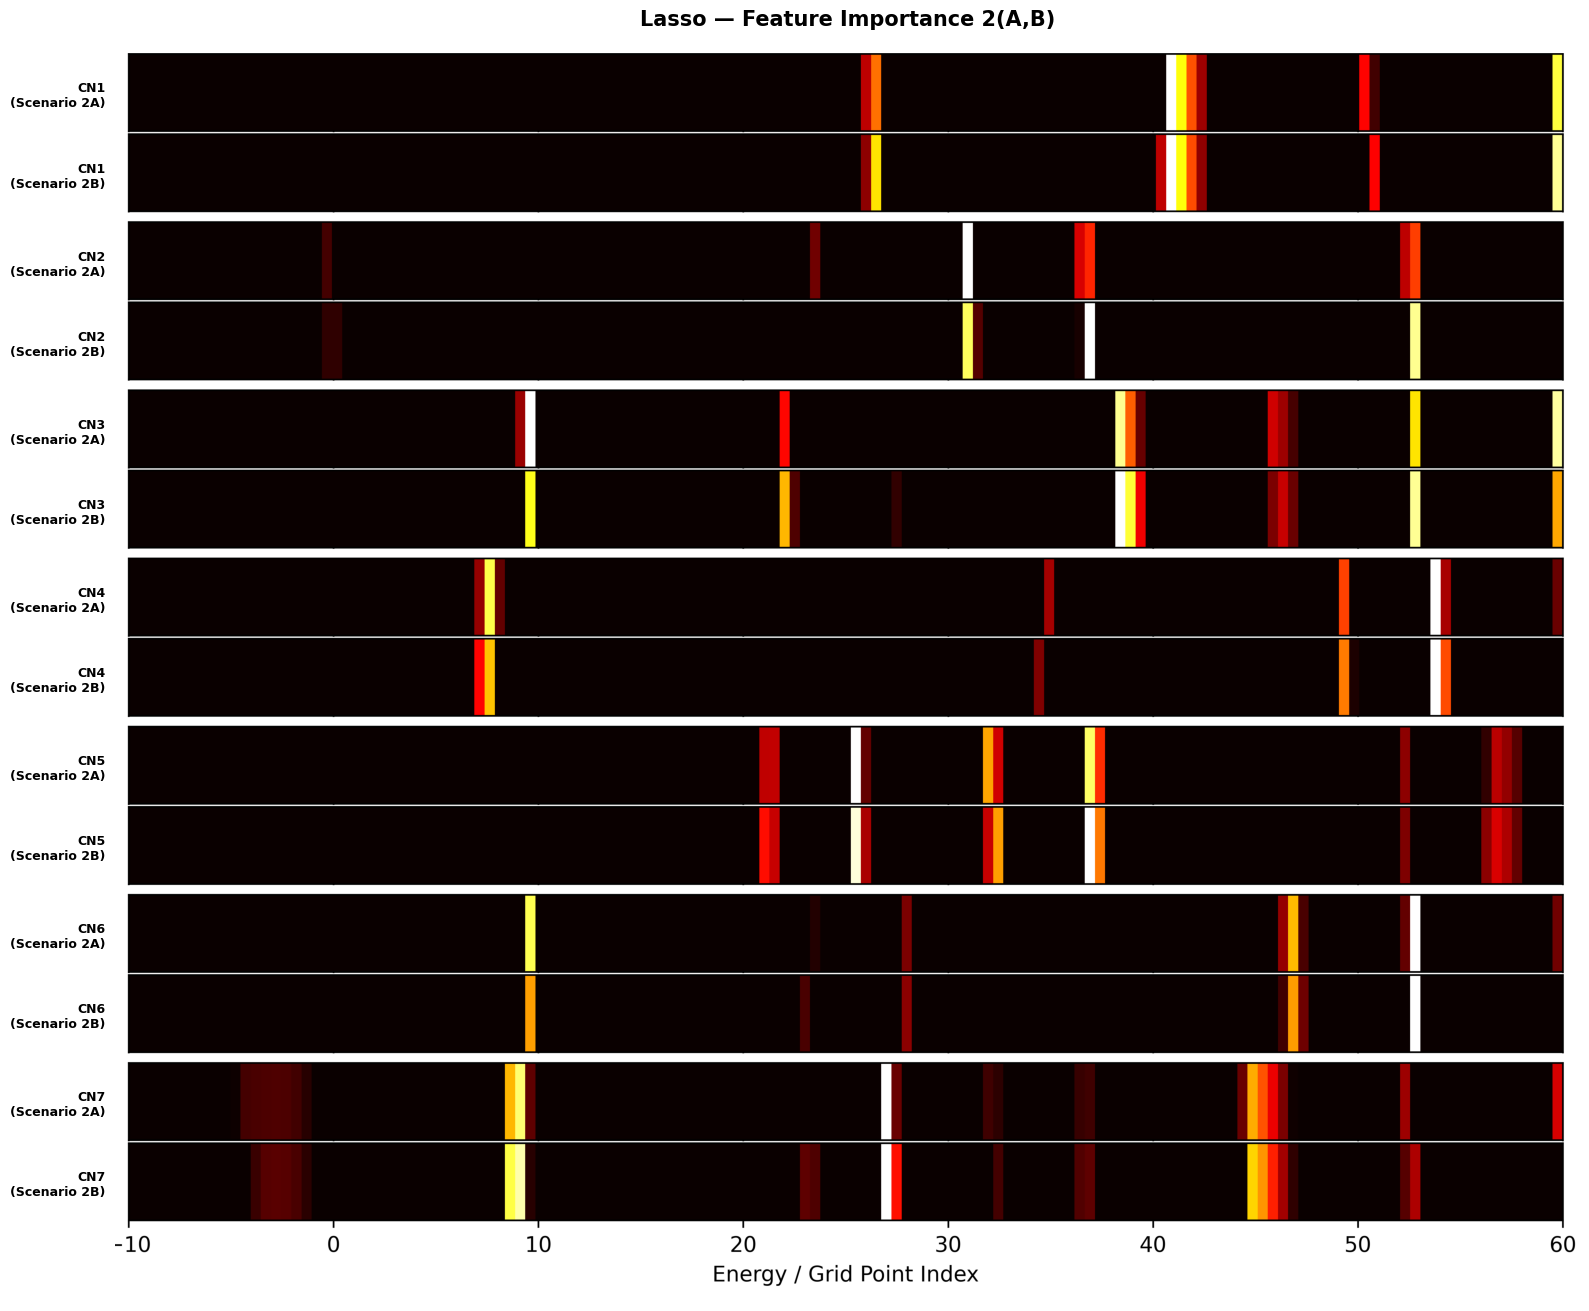

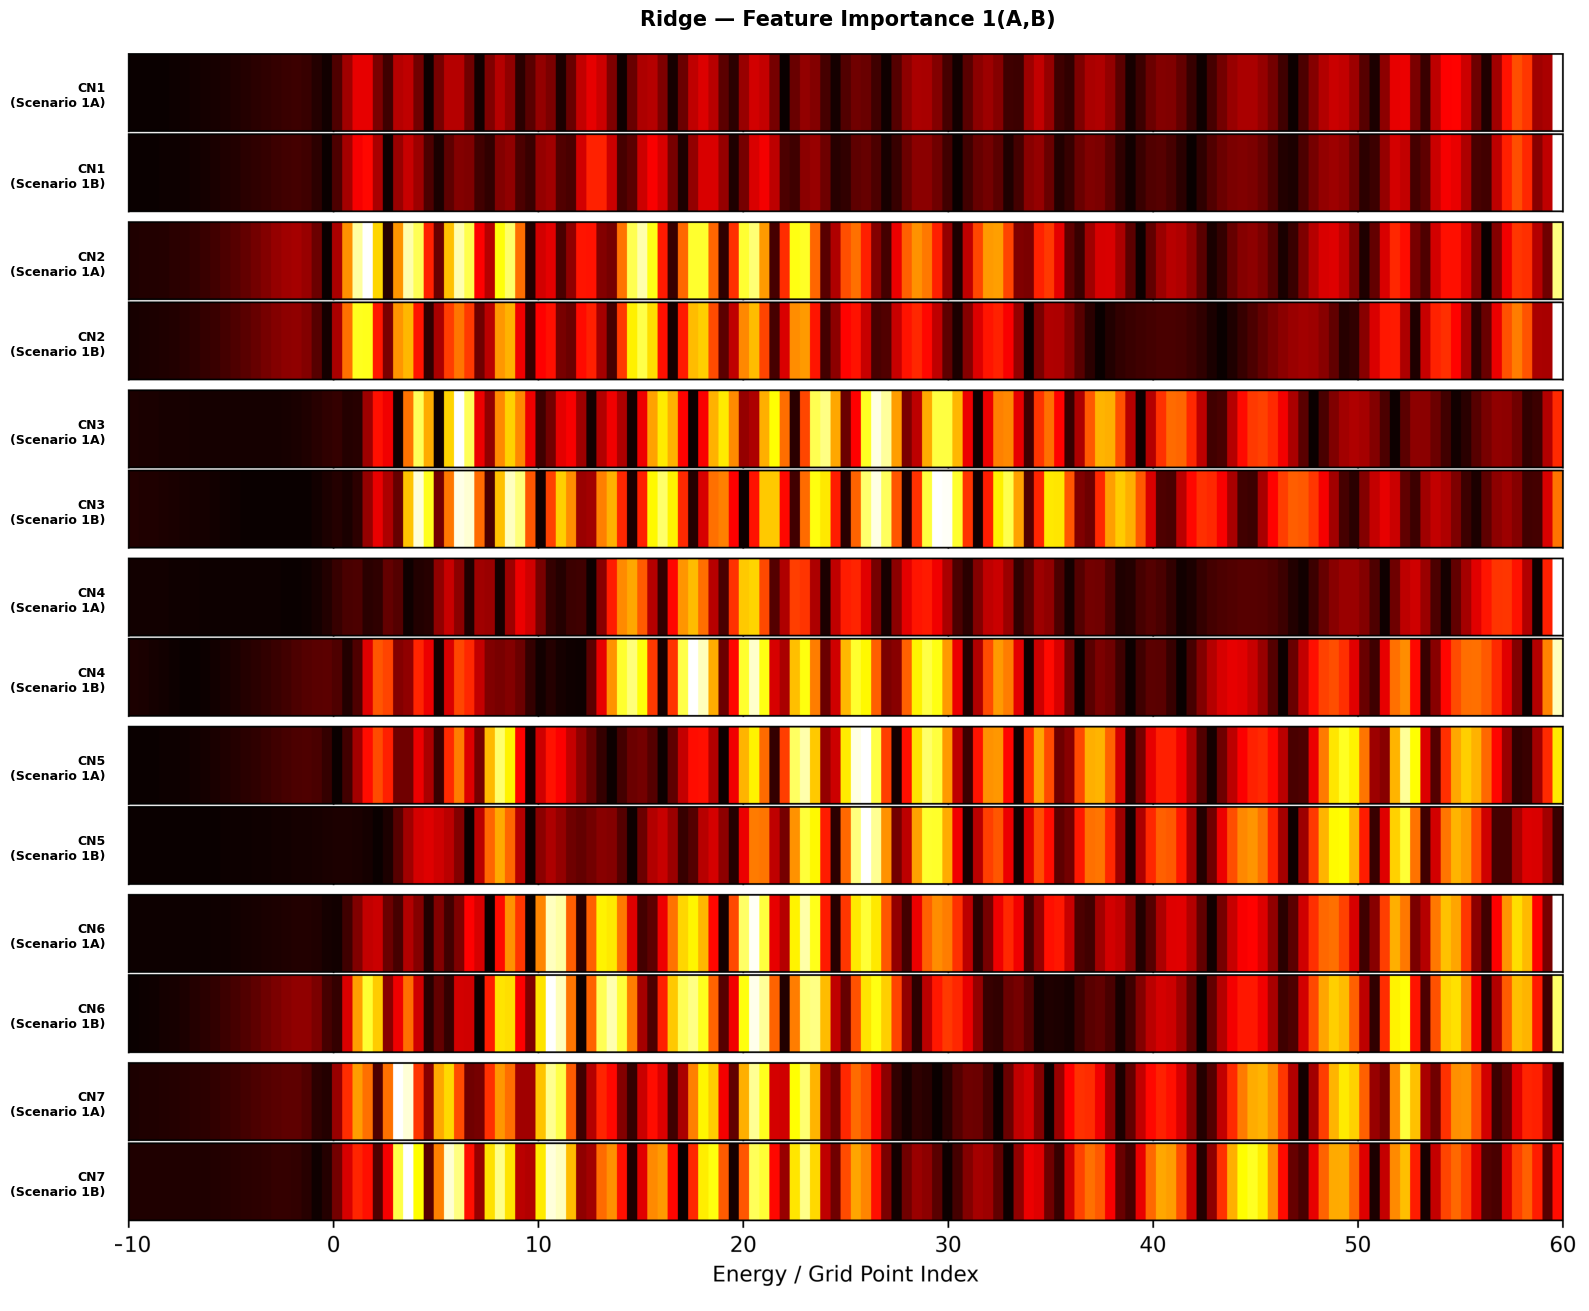

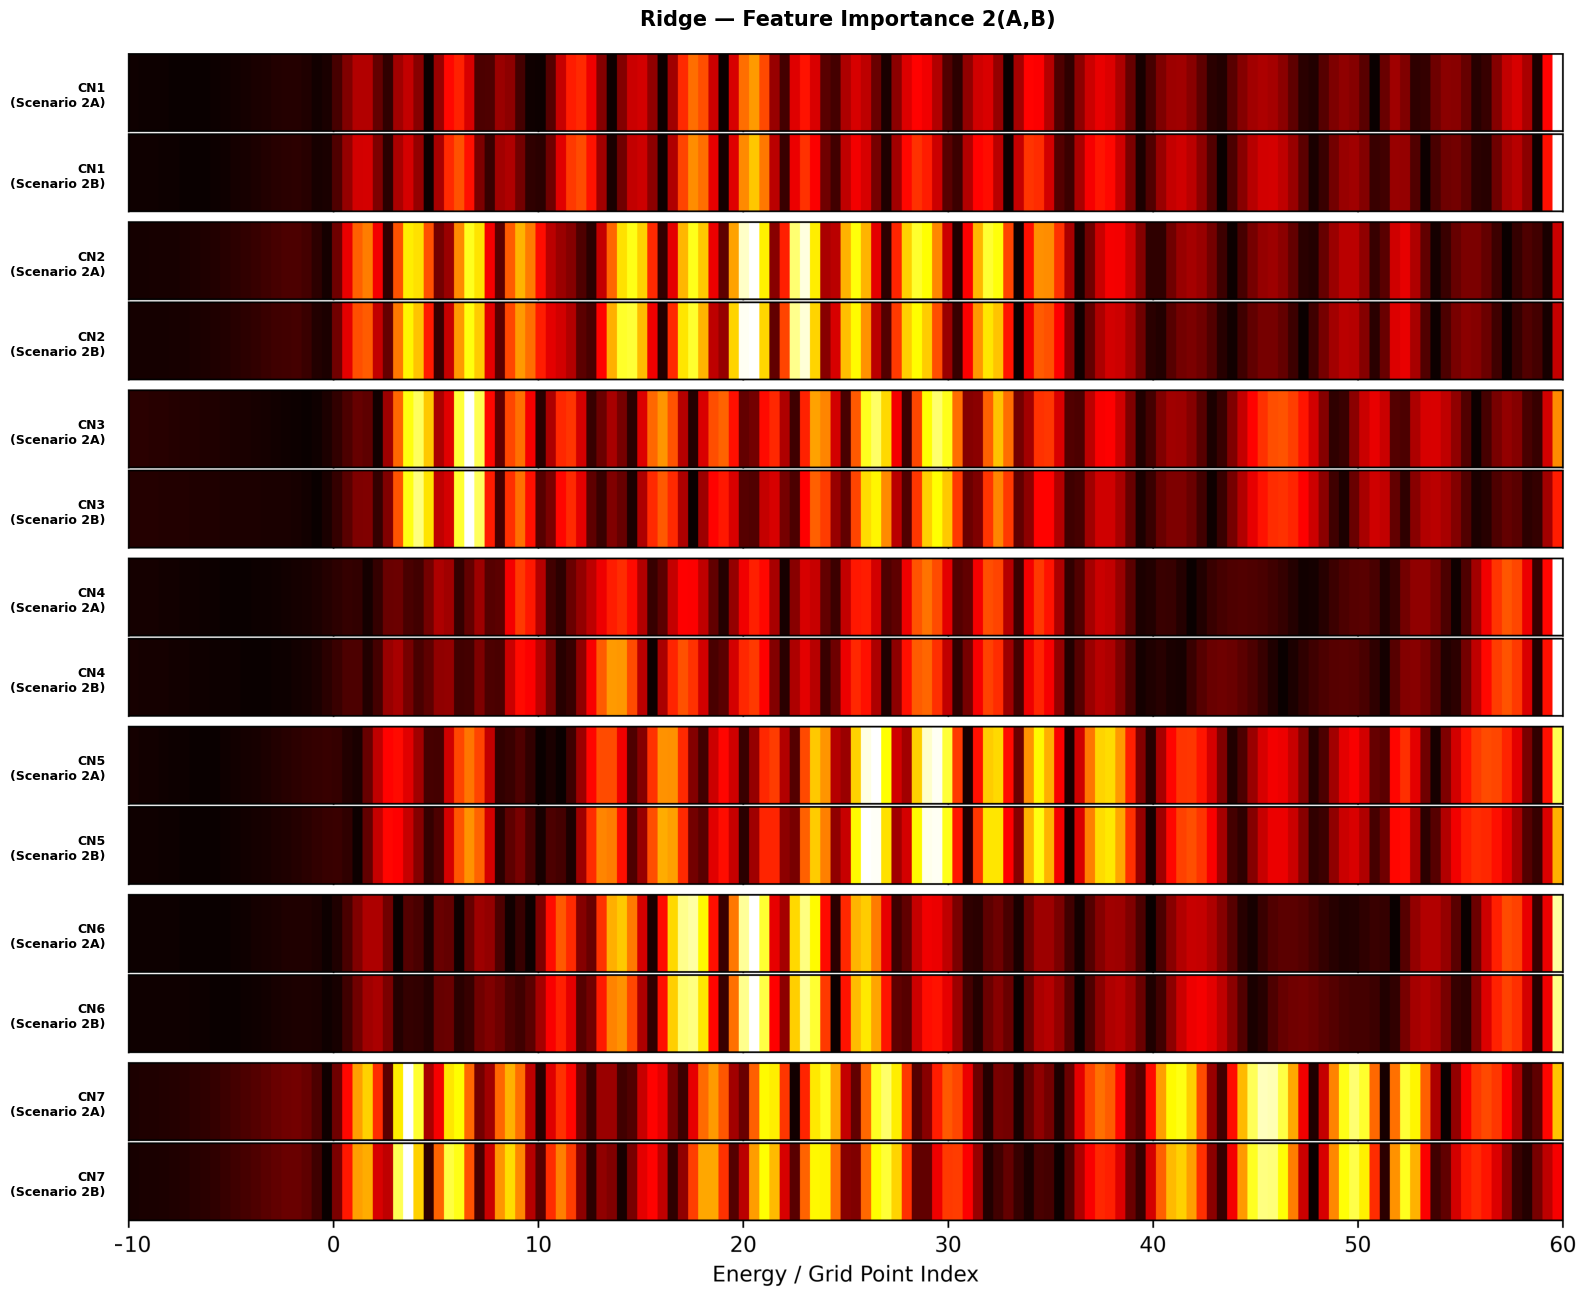

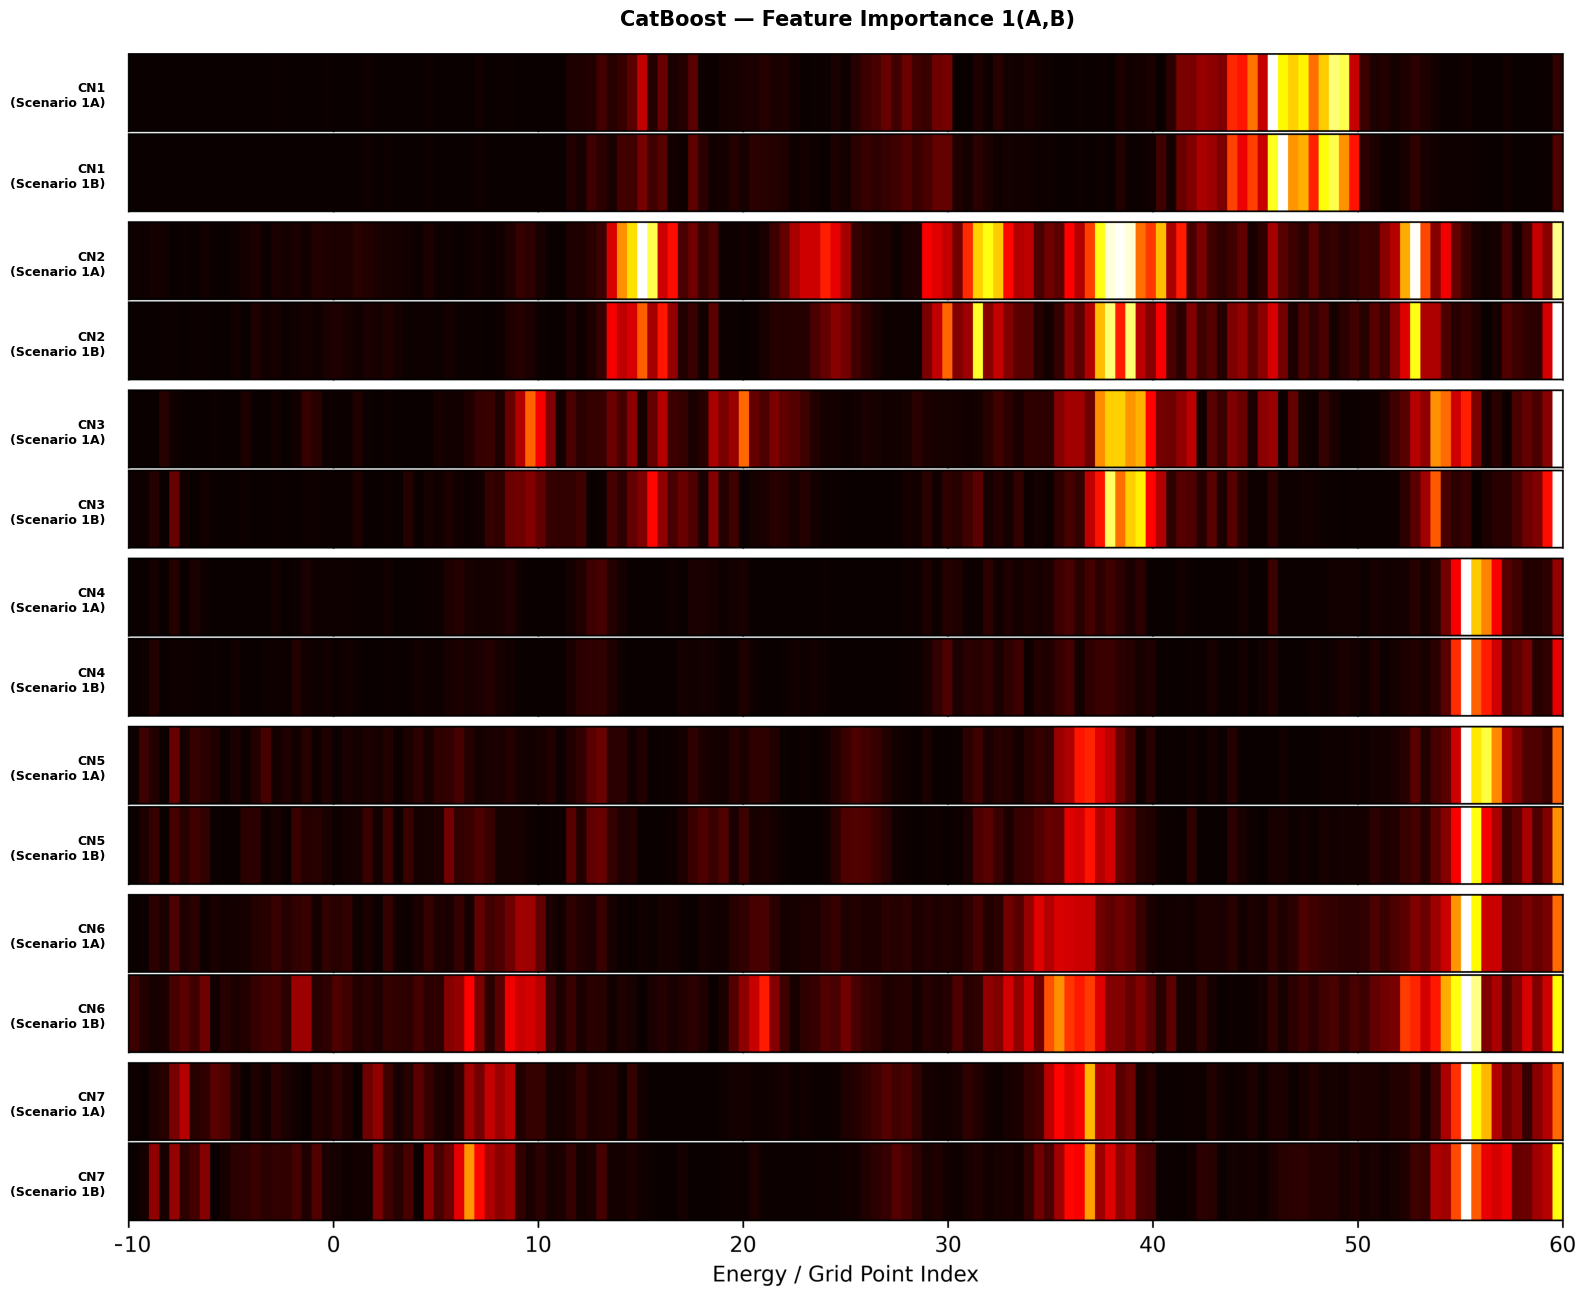

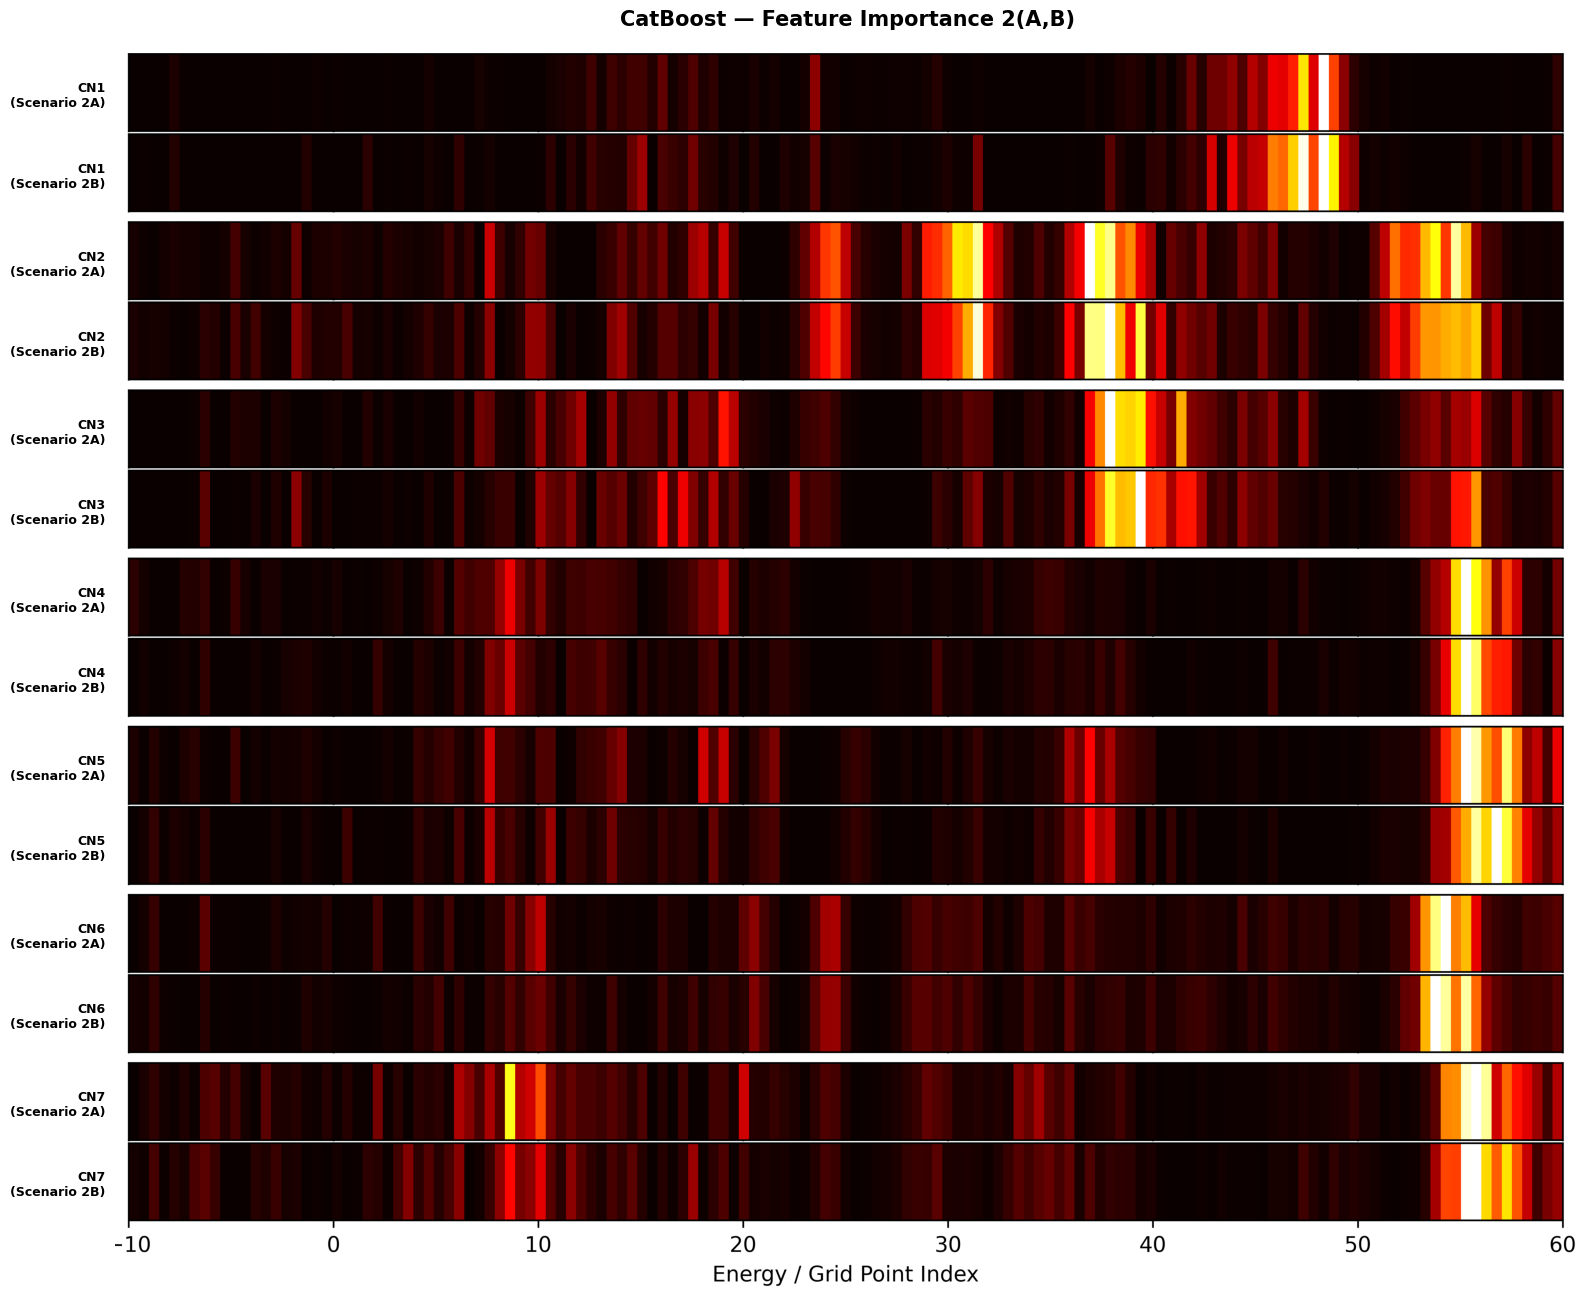

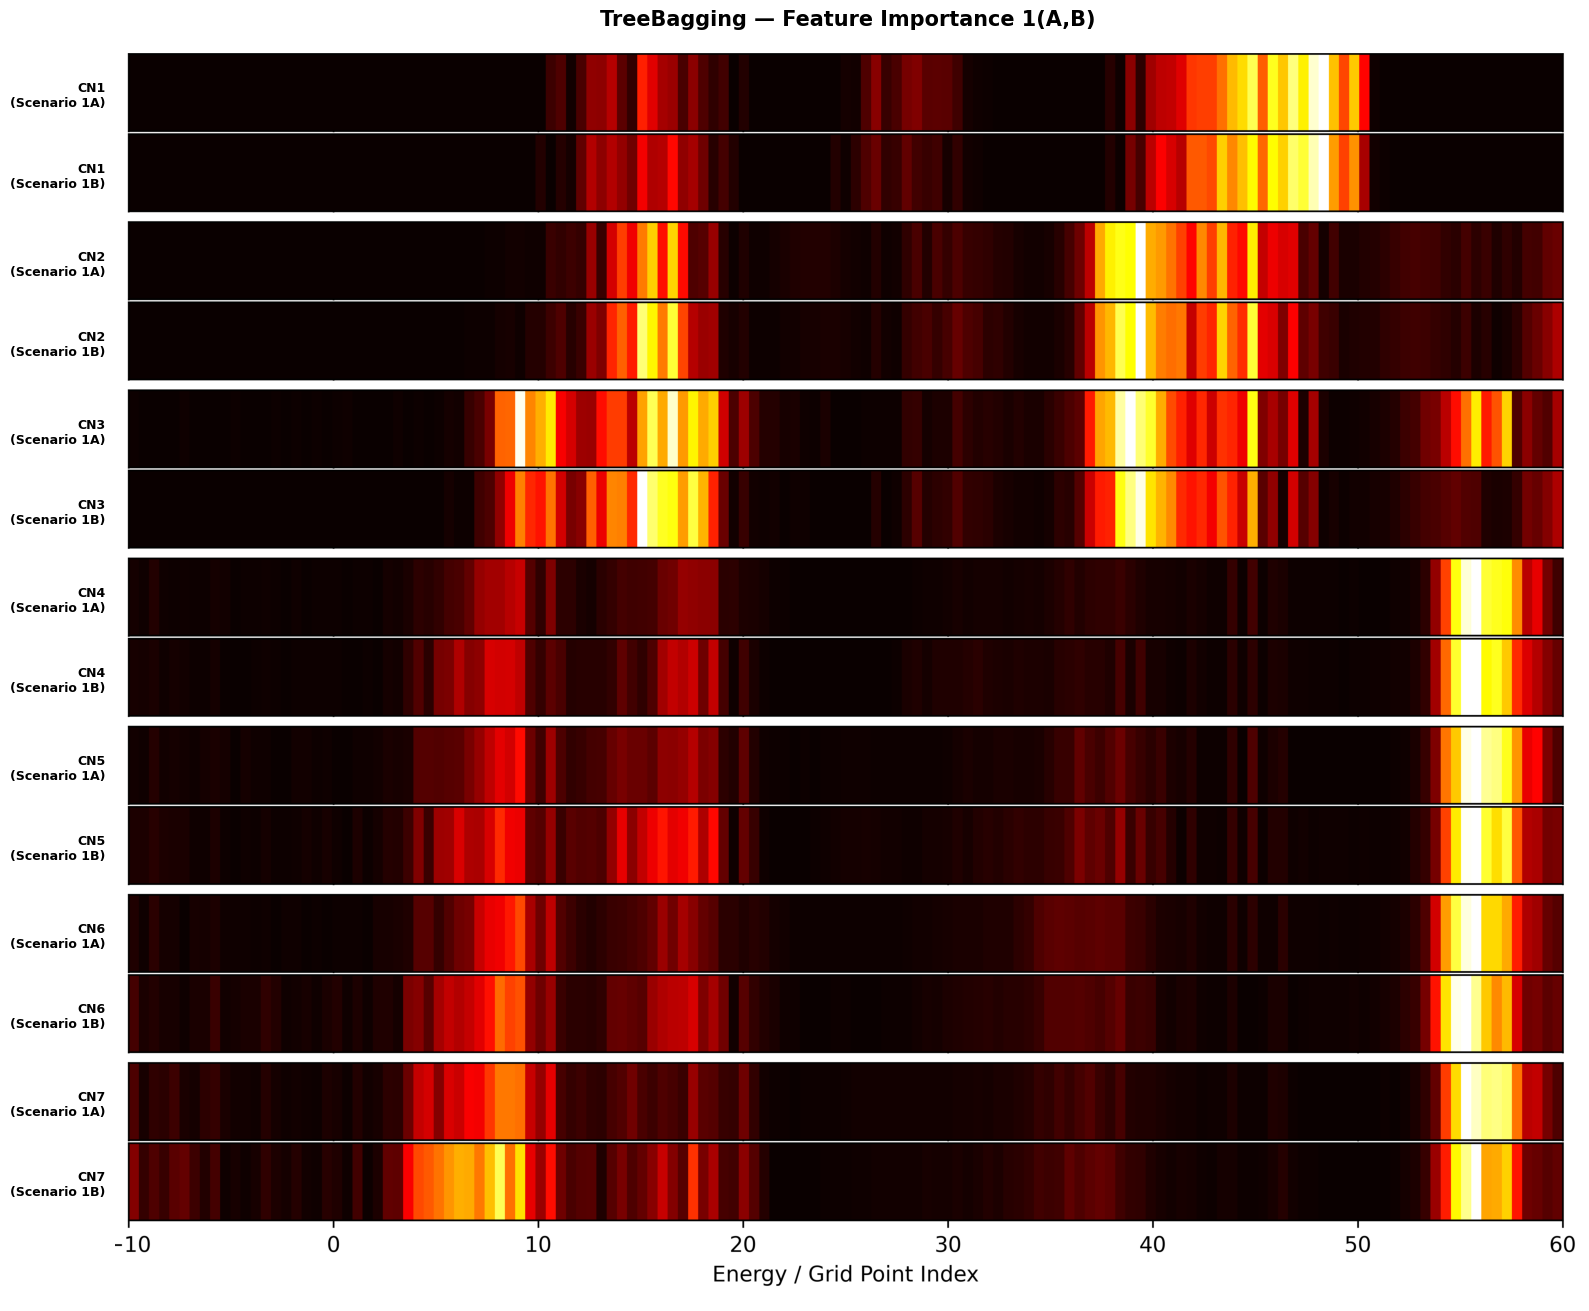

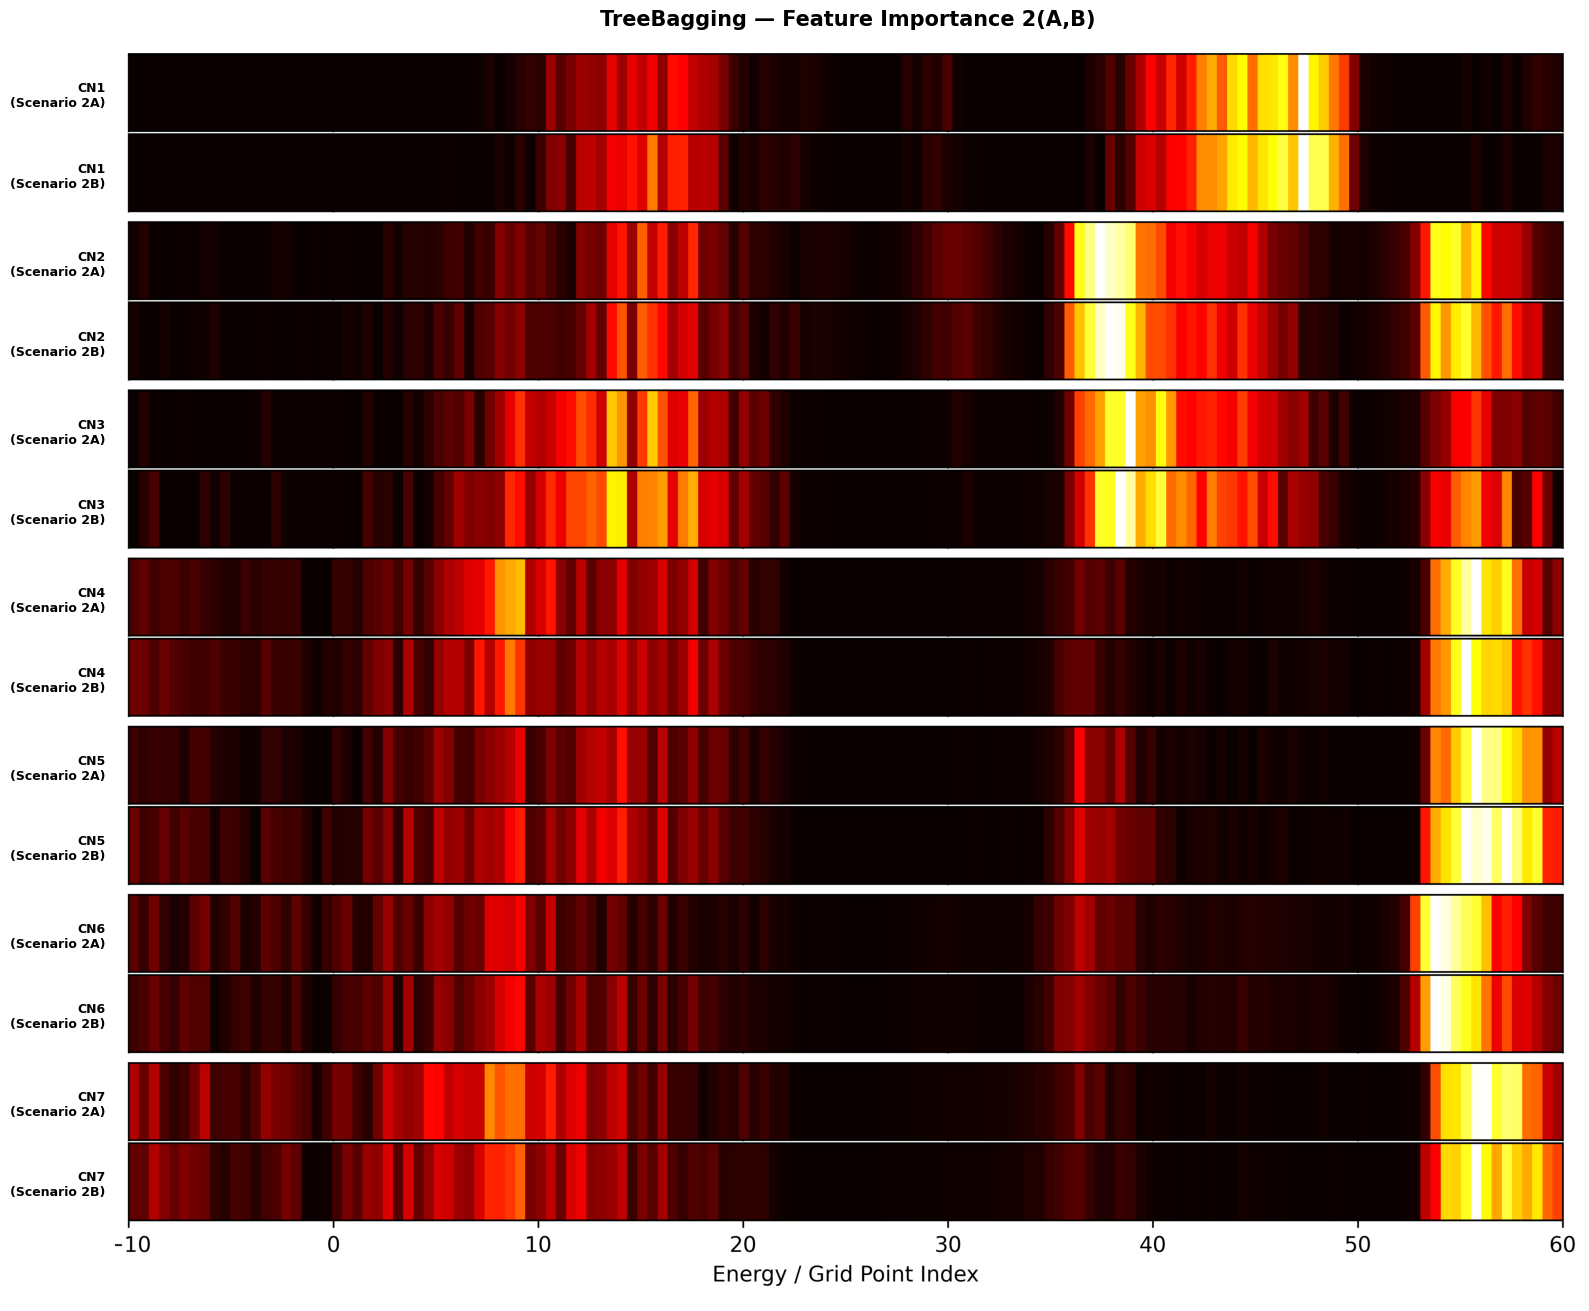

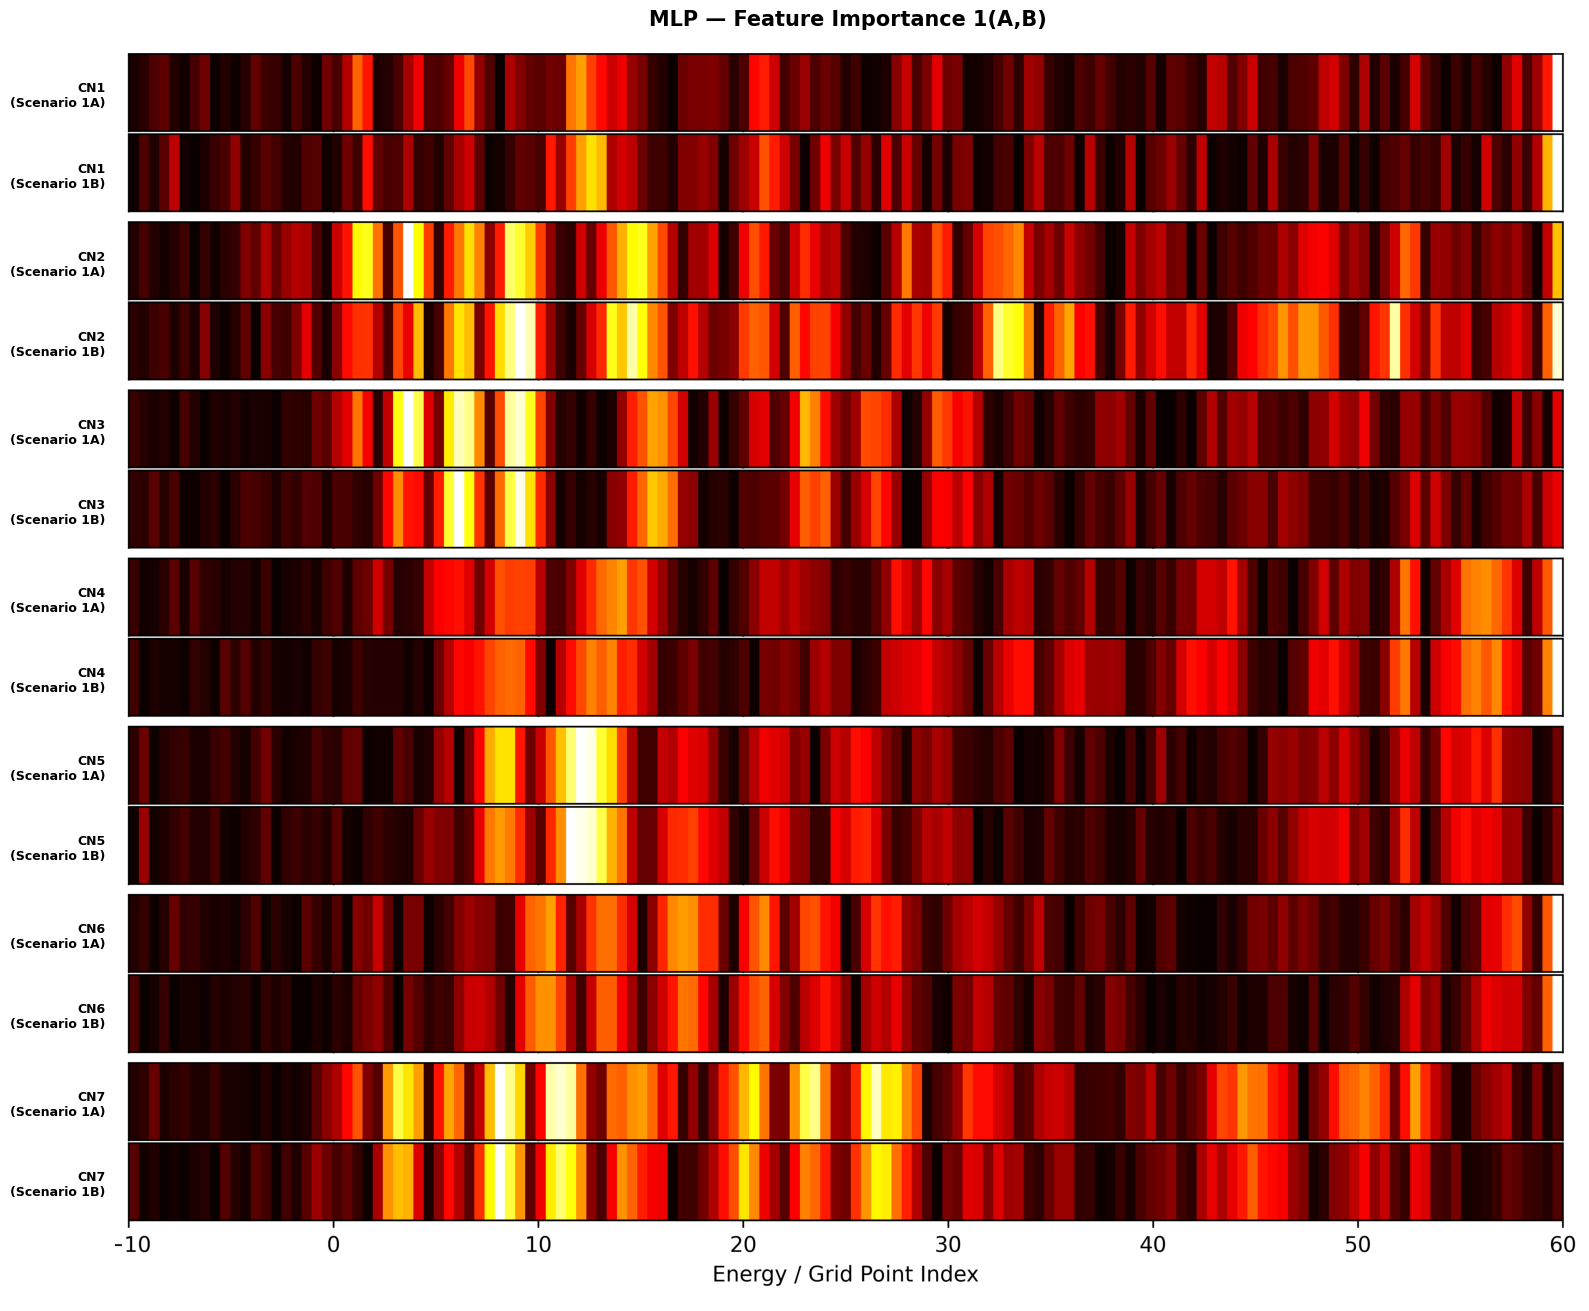

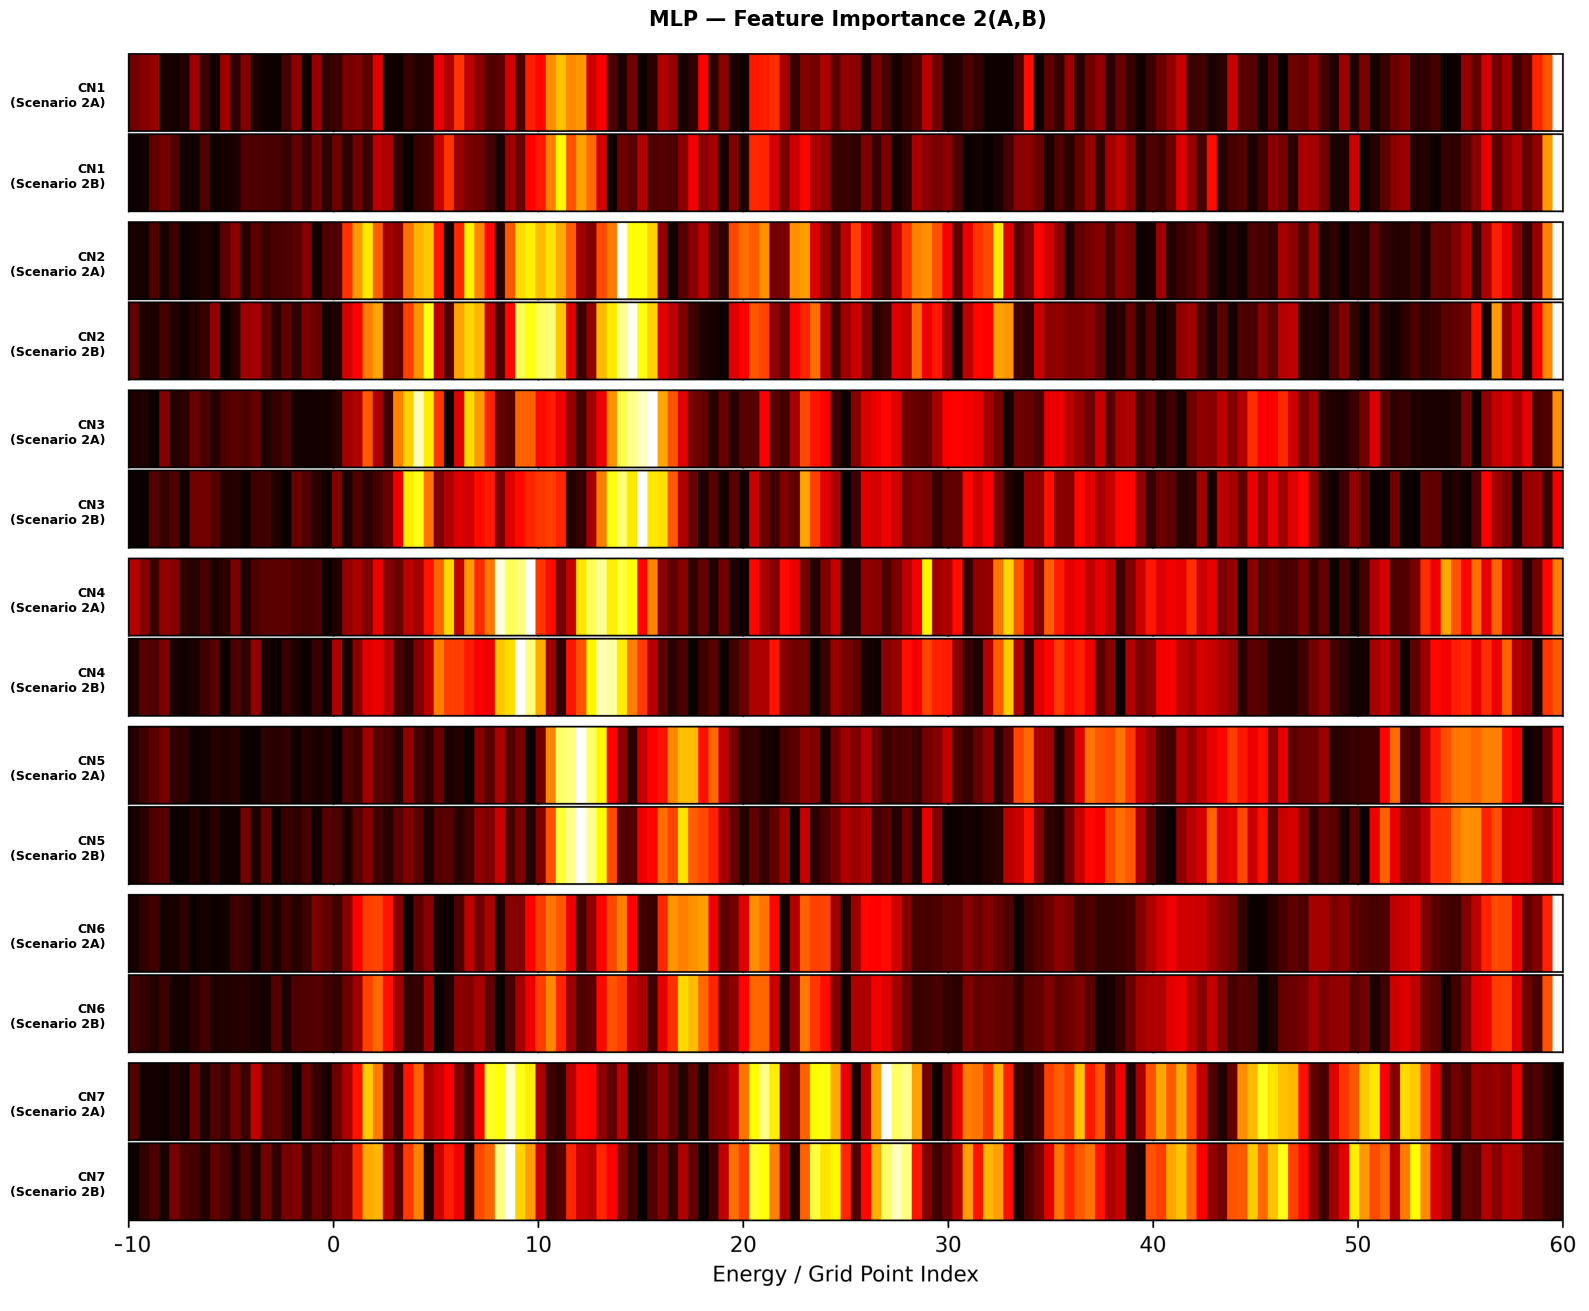

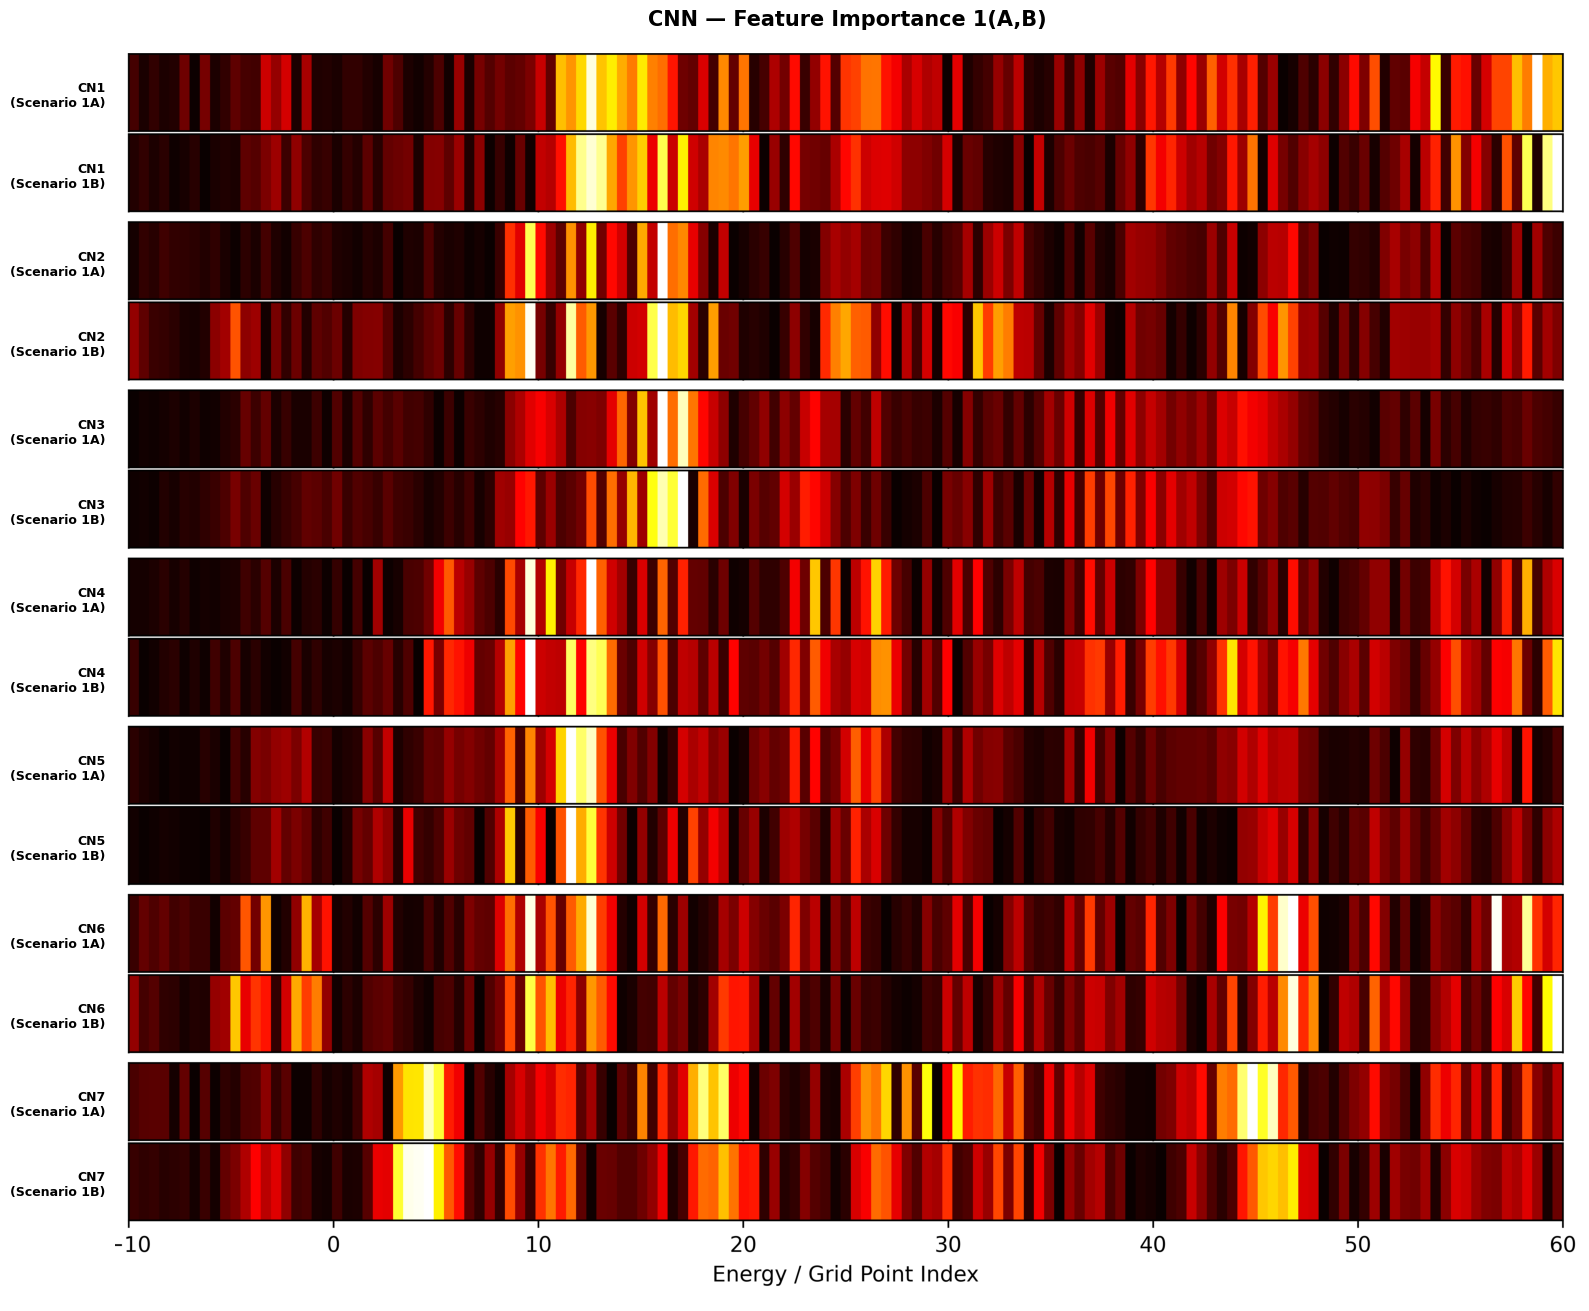

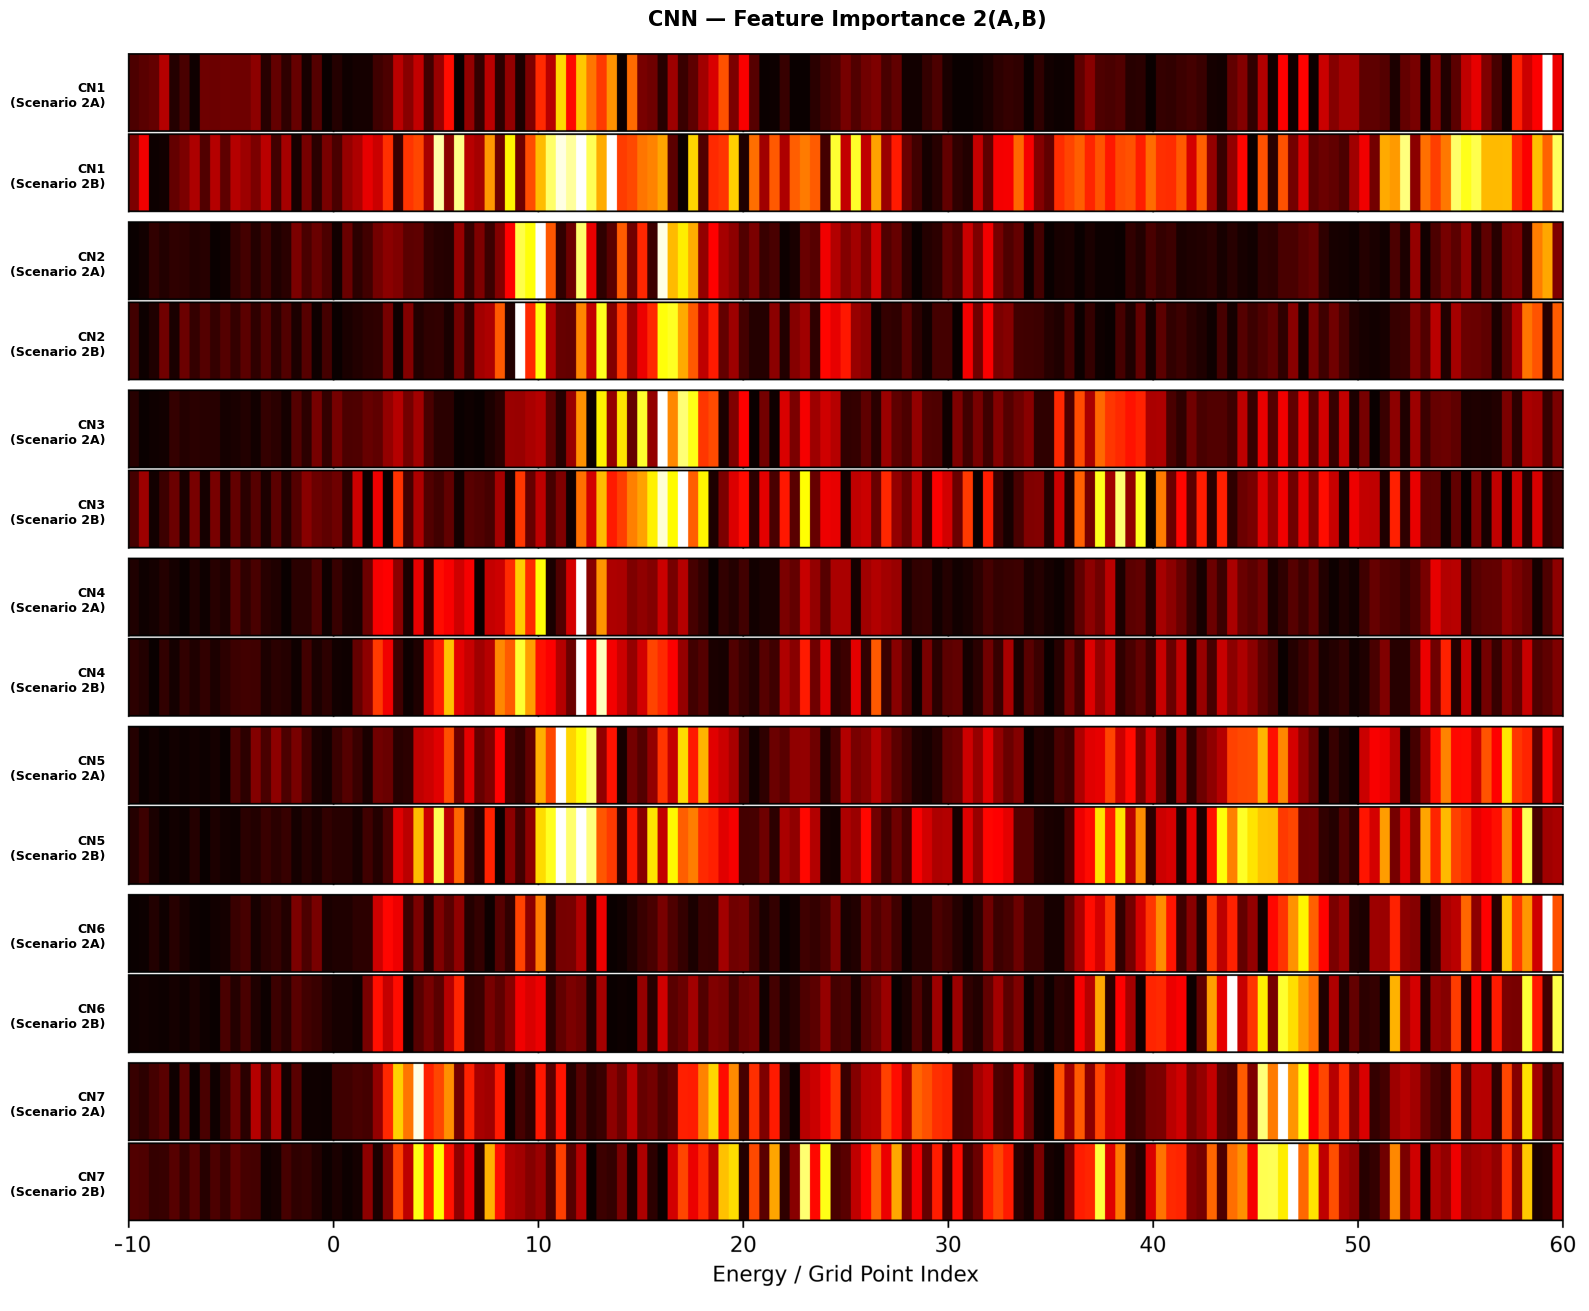

In [4]:
for m_name in models_names:
    for ind,(a,b) in enumerate(zip([name1A, name2A],[name1B, name2B])):
        path_a = list(ROOT_PATH.glob(f'**/{a}/**/{m_name}'))[0]
        path_b = list(ROOT_PATH.glob(f'**/{b}/**/{m_name}'))[0]
        save_path = Path(f'../processed_data/Results/FeatureMaps/{m_name}_Scenario_{ind+1}.png')
        plot_dual_scenario_auto_aligned(path_scenario_a=path_a,
                                        path_scenario_b=path_b,
                                        model_title=f'{m_name} — Feature Importance {ind+1}(A,B)',
                                        label_a=f'Scenario {ind+1}A',
                                        label_b=f'Scenario {ind+1}B',
                                        num_cn=7,
                                        separator_height = 30,
                                        save_path=save_path
                                       )